In [50]:
import numpy as np
import matplotlib.pyplot as plt
import os
import astropy.units as u
import json

import matplotlib.colors as mcolors
import matplotlib.lines as mlines

from transform_data import get_transformed_data, get_shock_mask
from field_config import field_lims, field_labels, field_scales

import flash_amr_tools
import h5py

In [51]:
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"
flash_output_dir = "/home/kwatanabe/Projects/cr-bowshocks/outputs_new"

# load the bowshock config
bowshock_config = json.load(open("../config/bowshock_config.json", "r"))["config"]


# list of fields we want to plot 1D slice of
fields = [ "dens", "pres"]

# times = [150, 300, 500] * u.kyr
# times = [50, 100, 200] * u.kyr
times = [30, 90, 120, 180] * u.kyr
times_lss = ["-", "--", ":"]

In [52]:
def get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns):

    field_slice = flash_amr_tools.get_slice(
        field_data,
        pos=0.0,
        axis=2,
        ref_lvl=ref_lvl,
        bbox=bbox,
        bsize=bsize,
        brefs=brefs,
        bns=bns,
    )
    # find zero value of y since we cannot slice again
    y_idx = np.digitize(0.0, yarr, right=True)
    return field_slice[:, y_idx]

def find_hdf5_file_from_time(time, sim_dir):
    """
    Find the HDF5 file corresponding to the given time in the simulation directory.
    """
    for file in os.listdir(sim_dir):
        if file.find("hdf5") != -1:
            pf = h5py.File(os.path.join(sim_dir, file), "r")
            time_from_file = (pf['real scalars'][0][1] * u.s).to(u.kyr)
            if np.isclose(time, time_from_file.value, atol=0.1):
                return os.path.join(sim_dir, file)
            
    return None

In [53]:
# # legend handles

# # time_handles = []
# # initial parameters
# for it, time in enumerate(times):

#     fig = plt.figure(figsize=(9,6))
#     gs = fig.add_gridspec(len(fields), 1, hspace=0, wspace=0.1)
#     axs = gs.subplots(sharex=True, sharey=False)

#     sim_handles = []

#     for sim_name in ["ISM-v30-MHD", "ISM-v30"]:
#         sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

#         # find the HDF5 file corresponding to the time
#         sim_file = find_hdf5_file_from_time(time.value, sim_dir)

#         blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

#         # open file to get the coordinate information
#         pf = h5py.File(sim_file, "r")
#         print(f"List of variables in file: {list(pf.keys())}")
#         ref_lvl = pf["refine level"][()][blist]
#         bbox = pf["bounding box"][()][blist]
#         bsize = pf["block size"][()][blist]

#         # get size of x and y
#         cube_size = np.zeros(3, dtype=int)
#         cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
#         cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
#         cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

#         # generate arrays for coordinates
#         low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
#         dxs = (up_cor - low_cor) / cube_size
#         xarr = (
#             np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
#         )
#         yarr = (
#             np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
#         )

#          # find the termination and outer shock as well
#         outer_shock_data = get_shock_mask(pf, blist, shock="outer")
#         outer_shock_1dslice = get_1dslice(outer_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#         # for the outer shock we only take the upstream quantity
#         x_outer_shock_arr_lt0 = xarr[(outer_shock_1dslice > 0) & (xarr < 0)]
#         x_outer_shock_arr_gt0 = xarr[(outer_shock_1dslice > 0) & (xarr > 0)]

#         term_shock_data = get_shock_mask(pf, blist, shock="term")
#         term_shock_1dslice = get_1dslice(term_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#         # for termiatnion shock we take both < 0 and > 0
#         x_term_shock_arr_lt0 = xarr[(term_shock_1dslice > 0) & (xarr < 0)]
#         x_term_shock_arr_gt0 = xarr[(term_shock_1dslice > 0) & (xarr > 0)]

#         print(x_term_shock_arr_lt0, x_term_shock_arr_gt0)

#         # now loop over different fields and plot
#         for i, field in enumerate(fields):
#             field_data = get_transformed_data(pf, field, blist)
#             field_1dslice = get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

#             # plot
#             axs[i].plot(
#                 (xarr * u.cm).to(u.pc),
#                 field_1dslice,
#                 lw=3.0,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="-"
#             )

#             # # plot
#             # axs[i].fill_between(
#             #     (xarr * u.cm).to(u.pc).value,
#             #     y1=0,
#             #     y2=field_lims[field][1],
#             #     # where=(outer_shock_1dslice > 0) & ((xarr * u.cm).to(u.pc).value < 0),
#             #     where=((xarr < x_outer_shock_arr[-1]) & (xarr > x_outer_shock_arr[0])),
#             #     alpha=0.5,
#             #     facecolor=None,
#             #     edgecolor=bowshock_config[sim_name]["color"],
#             #     hatch="//"
#             #     # ls="-"
#             # )

#             # # plot
#             # axs[i].fill_between(
#             #     (xarr * u.cm).to(u.pc).value,
#             #     y1=0,
#             #     y2=field_lims[field][1],
#             #     where=((xarr < x_term_shock_arr_lt0[-1]) & (xarr > x_term_shock_arr_lt0[0])),
#             #     alpha=0.5,
#             #     facecolor=None,
#             #     edgecolor=bowshock_config[sim_name]["color"],
#             #     hatch="|"
#             #     # ls="-"
#             # )

#             # # plot
#             # axs[i].fill_between(
#             #     (xarr * u.cm).to(u.pc).value,
#             #     y1=0,
#             #     y2=field_lims[field][1],
#             #     where=((xarr < x_term_shock_arr_gt0[-1]) & (xarr > x_term_shock_arr_gt0[0])),
#             #     alpha=0.5,
#             #     facecolor=None,
#             #     edgecolor=bowshock_config[sim_name]["color"],
#             #     hatch="|"
#             #     # ls="-"
#             # )

#             # plot
#             axs[i].axvline(
#                 (np.mean(x_outer_shock_arr_lt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="--",
#                 lw=3.0
#                 # ls="-"
#             )
#             # plot
#             axs[i].axvline(
#                 (np.mean(x_outer_shock_arr_gt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls="--",
#                 lw=3.0
#                 # ls="-"
#             )

#             # plot
#             axs[i].axvline(
#                 (np.mean(x_term_shock_arr_gt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls=":",
#                 lw=3.0
#                 # ls="-"
#             )
#             # plot
#             axs[i].axvline(
#                 (np.mean(x_term_shock_arr_lt0) * u.cm).to(u.pc).value,
#                 alpha=0.7,
#                 color=bowshock_config[sim_name]["color"],
#                 ls=":",
#                 lw=3.0
#                 # ls="-"
#             )

#             # limits
#             axs[i].set_xlim(xmin=-15, xmax=30)
#             axs[i].set_ylim(field_lims[field])

#             # scale
#             axs[i].set_yscale(field_scales[field])

#             # labels
#             axs[-1].set_xlabel("$x$ / pc", fontsize=25)
#             axs[i].set_ylabel(field_labels[field], fontsize=25)

#             # ticks
#             axs[i].tick_params(
#                 axis="both",
#                 direction="in",
#                 which="major",
#                 size=8,
#                 labelsize=18,
#                 top=True,
#                 right=True,
#             )
#             axs[i].tick_params(
#                 axis="both",
#                 direction="in",
#                 which="minor",
#                 size=6,
#                 labelsize=16,
#                 top=True,
#                 right=True,
#             )

#         sim_handles.append(
#             mlines.Line2D(
#                 [0], [0], lw=3.0, color=bowshock_config[sim_name]["color"], label=bowshock_config[sim_name]["label"]
#             )
#         )

#         # time_handles.append(
#         #     mlines.Line2D(
#         #         [0], [0], lw=3.0, color="k", label=f"t={time:.0f}", ls=times_lss[it]
#         #     )
#         # )

#     handles = [sim_handles[0], sim_handles[1], mlines.Line2D(
#                 [0], [0], lw=3.0, color="k", label="Outer Shock", ls="--"
#             ),
#             mlines.Line2D(
#                 [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
#             )]
#     fig.legend(handles=handles, prop={"size":18}, bbox_to_anchor=[0.8,1.07], ncol=2, handleheight=2.4, labelspacing=0.05, frameon=False, borderaxespad=0.0)

#     axs[0].annotate(f"t={time:.0f}", xy=(18.5, 3e-29), fontsize=24)


# # fig.legend(handles=time_handles, prop={"size":14})

#     fig.savefig(f"{fig_dir}/1dslice_t{time.value}kyr.pdf", dpi=300, bbox_inches="tight")

In [54]:
textpos_y = {
    "dens" : 3e-24,
    "vel" : 5e3,
    "pres" : 5e4,
    "mag" : 1e-5
}

ISM-v100
/home/kwatanabe/Projects/cr-bowshocks/outputs_new/ISM_v100_CR/starISM_hdf5_plt_cnt_0022


Exception: 

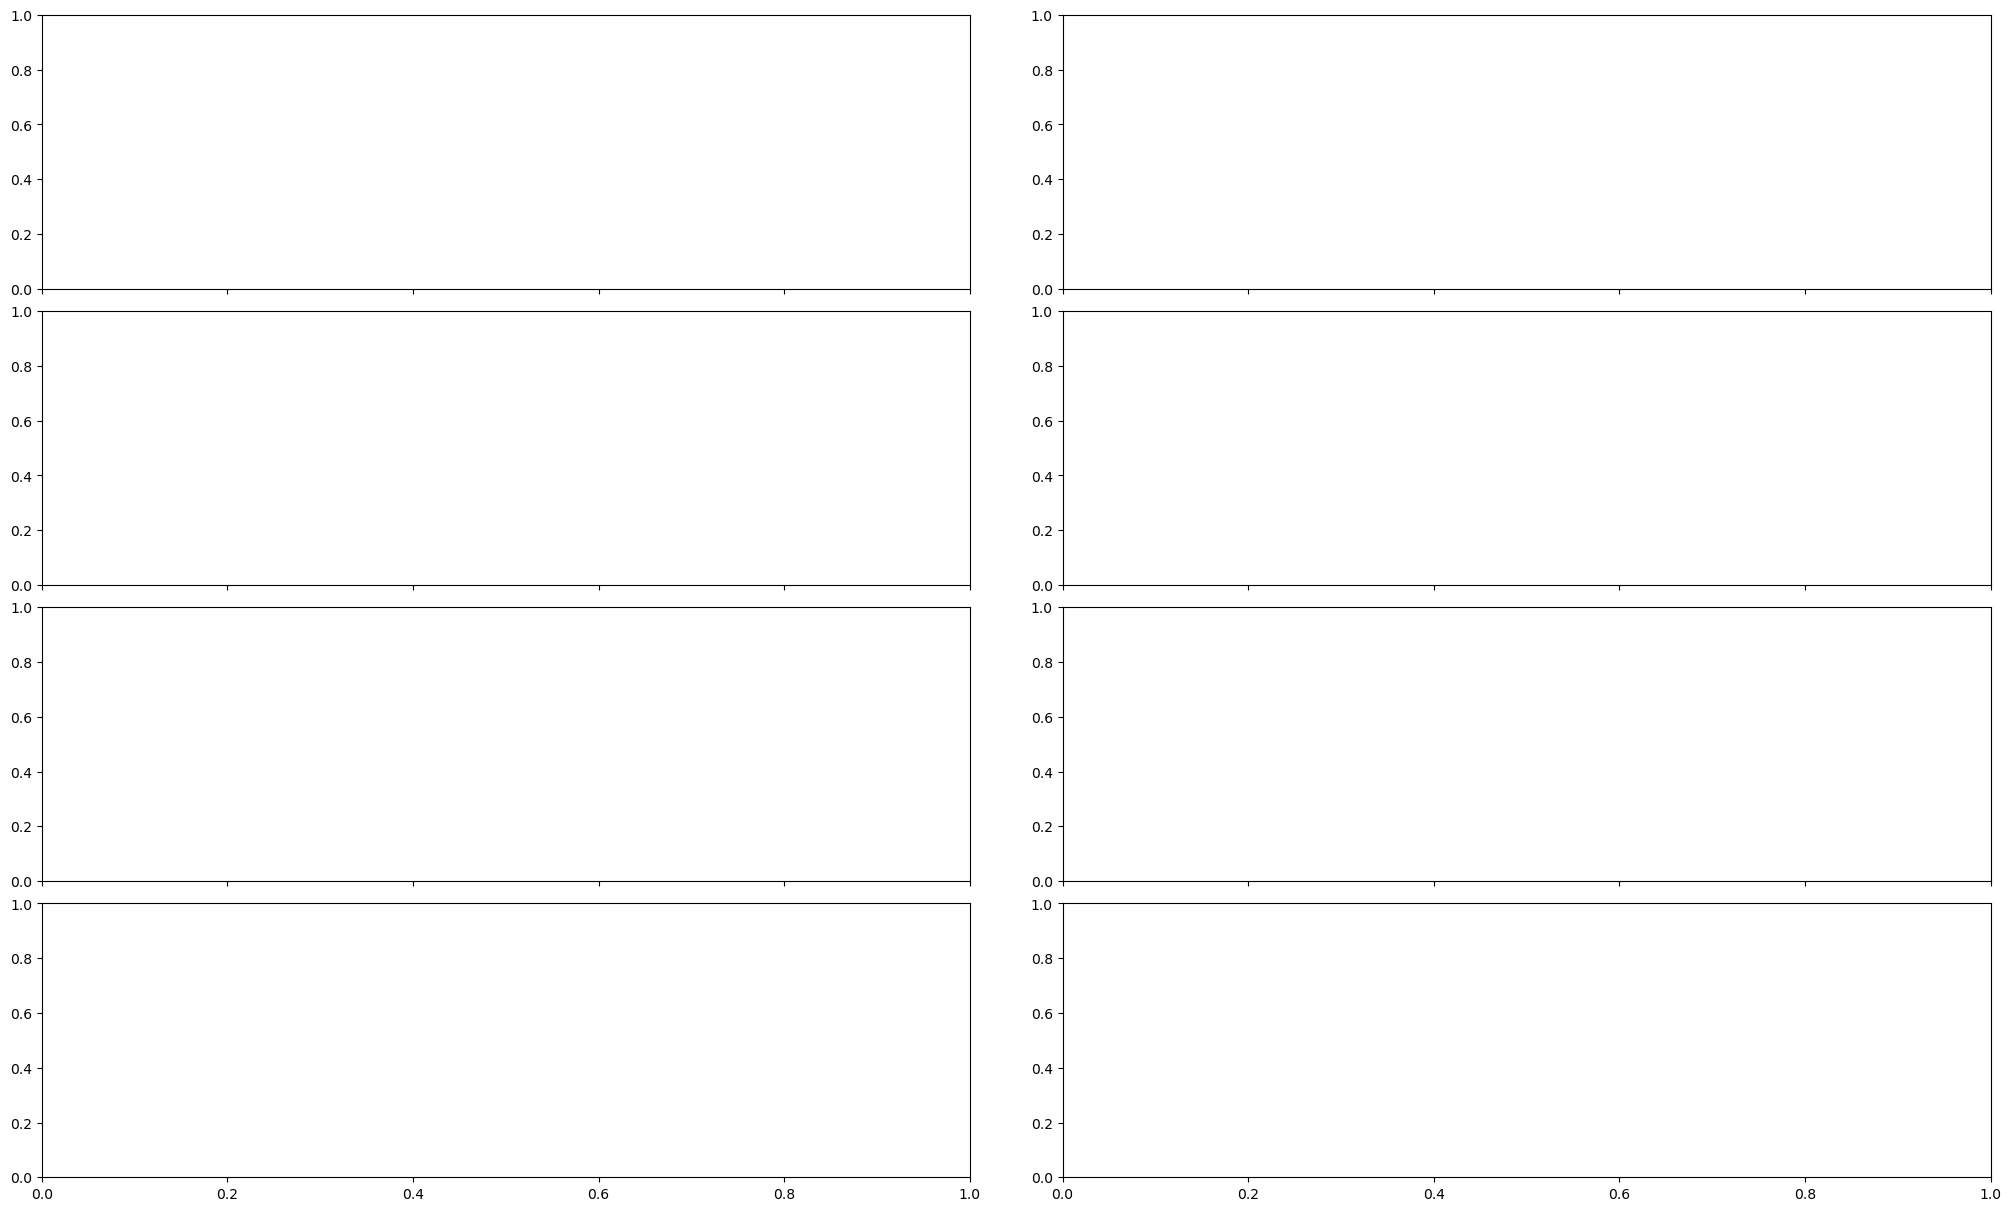

In [57]:
fig = plt.figure(figsize=(20, 12), constrained_layout=True)
gs = fig.add_gridspec(len(times),len(fields), hspace=0, wspace=0.05)
axs = gs.subplots(sharex=True, sharey=False)

axs_flattened = axs.flatten()

# time_handles = []
# initial parameters
for it, time in enumerate(times):

    sim_handles = []

    for sim_name in ["ISM-v100"]:
        print(sim_name)
        sim_dir = os.path.join(flash_output_dir, bowshock_config[sim_name]["sim_dir"])

        # find the HDF5 file corresponding to the time
        sim_file = find_hdf5_file_from_time(180, sim_dir)

        print(sim_file)

        raise Exception()

        blist, brefs, bns = flash_amr_tools.get_true_blocks(sim_file)

        # open file to get the coordinate information
        pf = h5py.File(sim_file, "r")
        print(f"List of variables in file: {list(pf.keys())}")
        ref_lvl = pf["refine level"][()][blist]
        bbox = pf["bounding box"][()][blist]
        bsize = pf["block size"][()][blist]

        # get size of x and y
        cube_size = np.zeros(3, dtype=int)
        cube_size[0] = int(bns[0]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[1] = int(bns[1]) * 2 ** (brefs[0] - brefs[1] + 3)
        cube_size[2] = int(bns[2]) * 2 ** (brefs[0] - brefs[1] + 3)

        # generate arrays for coordinates
        low_cor, up_cor = bbox[0, :, 0], bbox[-1, :, 1]
        dxs = (up_cor - low_cor) / cube_size
        xarr = (
            np.linspace(low_cor[0], up_cor[0], cube_size[0], endpoint=False) + 0.5 * dxs[0]
        )
        yarr = (
            np.linspace(low_cor[1], up_cor[1], cube_size[1], endpoint=False) + 0.5 * dxs[1]
        )

         # find the termination and outer shock as well
        outer_shock_data = get_shock_mask(pf, blist, shock="outer")
        outer_shock_1dslice = get_1dslice(outer_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

        # raise Exception()

        # for the outer shock we only take the upstream quantity
        x_outer_shock_arr_lt0 = xarr[(outer_shock_1dslice > 0) & (xarr < 0)]
        x_outer_shock_arr_gt0 = xarr[(outer_shock_1dslice > 0) & (xarr > 0)]

        print(x_outer_shock_arr_lt0, x_outer_shock_arr_gt0)

        term_shock_data = get_shock_mask(pf, blist, shock="term")
        term_shock_1dslice = get_1dslice(term_shock_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

        # for termiatnion shock we take both < 0 and > 0
        x_term_shock_arr_lt0 = xarr[(term_shock_1dslice > 0) & (xarr < 0)]
        x_term_shock_arr_gt0 = xarr[(term_shock_1dslice > 0) & (xarr > 0)]

        # now loop over different fields and plot
        for i, field in enumerate(fields):
            field_data = get_transformed_data(pf, field, blist)
            field_1dslice = get_1dslice(field_data, yarr, ref_lvl, bbox, bsize, brefs, bns)

            # plot
            axs_flattened[2 * it + i].plot(
                (xarr * u.cm).to(u.pc),
                field_1dslice,
                lw=3.0,
                color=bowshock_config[sim_name]["color"],
                ls="-"
            )

            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_outer_shock_arr_lt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls="--",
                lw=3.0
                # ls="-"
            )
            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_outer_shock_arr_gt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls="--",
                lw=3.0
                # ls="-"
            )

            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_term_shock_arr_gt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls=":",
                lw=3.0
                # ls="-"
            )
            # plot
            axs_flattened[2 * it + i].axvline(
                (np.mean(x_term_shock_arr_lt0) * u.cm).to(u.pc).value,
                alpha=0.7,
                color=bowshock_config[sim_name]["color"],
                ls=":",
                lw=3.0
                # ls="-"
            )

            # limits
            axs_flattened[2 * it + i].set_xlim(xmin=-15, xmax=30)
            axs_flattened[2 * it + i].set_ylim(field_lims[field])

            # scale
            axs_flattened[2 * it + i].set_yscale(field_scales[field])

            # labels
            axs_flattened[2 * it + i].set_ylabel(field_labels[field], fontsize=25)

            # ticks
            axs_flattened[2 * it + i].tick_params(
                axis="both",
                direction="in",
                which="major",
                size=8,
                labelsize=18,
                top=True,
                right=True,
            )
            axs_flattened[2 * it + i].tick_params(
                axis="both",
                direction="in",
                which="minor",
                size=6,
                labelsize=16,
                top=True,
                right=True,
            )

            axs_flattened[2 * it + i].annotate(f"t={time.value:.0f} kyr", xy=(21.5, textpos_y[field]), fontsize=22)

            if (2 * it + i) >= 6:  # TODO: change this to a more general condition
                axs_flattened[2 * it + i].set_xlabel("$x$ / pc", fontsize=25)


        sim_handles.append(
            mlines.Line2D(
                [0], [0], lw=3.0, color=bowshock_config[sim_name]["color"], label=bowshock_config[sim_name]["label"]
            )
        )

        # time_handles.append(
        #     mlines.Line2D(
        #         [0], [0], lw=3.0, color="k", label=f"t={time:.0f}", ls=times_lss[it]
        #     )
        # )

# handles = [sim_handles[0], sim_handles[1], mlines.Line2D(
#             [0], [0], lw=3.0, color="k", label="Outer Shock", ls="--"
#         ),
#         mlines.Line2D(
#             [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
#         )]
sim_handles.append(
    mlines.Line2D(
        [0], [0], lw=3.0, color="k", label="Outer Shock", ls="--"
    )
)
sim_handles.append(
    mlines.Line2D(
        [0], [0], lw=3.0, color="k", label="Termination Shock", ls=":"
    )
)
fig.legend(handles=sim_handles, prop={"size":20},  ncol=4, frameon=False, borderaxespad=4.0, mode='expand', loc="upper left", bbox_to_anchor=(0.02, 1.15, 1, 0),)
# fig.subplots_adjust(top=0.88)
# axs_flattened[6].set_xlabel("$x$ / pc", fontsize=25)

#     axs[0].annotate(f"t={time:.0f}", xy=(18.5, 3e-29), fontsize=24)


# # fig.legend(handles=time_handles, prop={"size":14})

# fig.savefig(f"{fig_dir}/1dslice_all.pdf", dpi=300, bbox_inches="tight")